a port from: https://huggingface.co/spaces/anton-bushuiev/DreaMS 
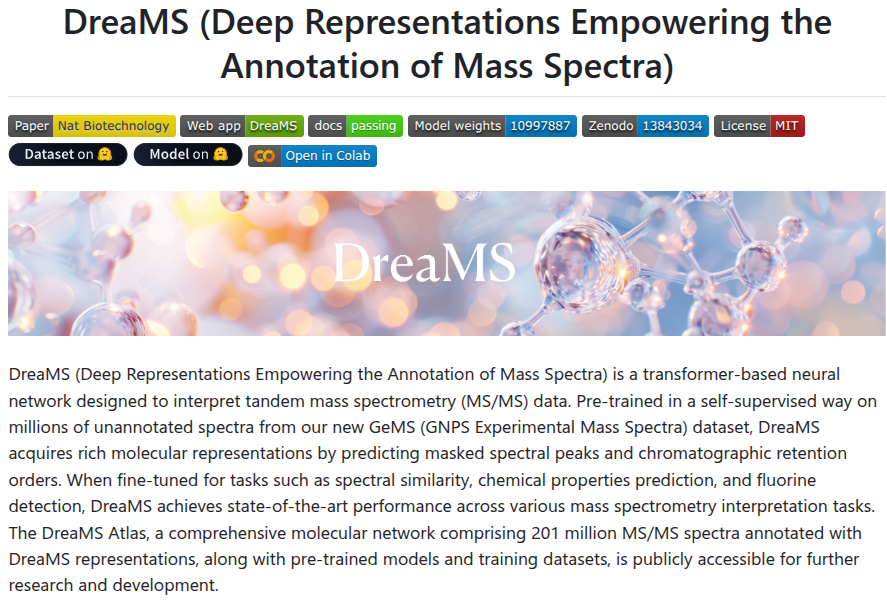


In [ ]:
try:
    import rdkit
except:
    !pip install rdkit

import sys
sys.path.append("/kaggle/input/datasets/hengck23/hengck23-dreams-enveda-casmi26")

import numpy as np
import pandas as pd
from pprint import pprint
import pickle
import torch

from dreams_html_results_v2 import show_dreams_tsv, to_rich_tsv
from dreams_minimal_model import *

DREAMS_DIR = "/kaggle/input/datasets/hengck23/hengck23-dreams-enveda-casmi26"
KAGGLE_DIR="/kaggle/input/competitions/enveda-CASMI26-molecule-id-mass-spectra"
print("import ok!!!")

In [ ]:

#data processing
def df_to_data(df):
    spectra = np.empty(len(df),dtype=object)
    precursor_mz = []
    meta = []

    for i, row in df.iterrows():
        mzs = np.asarray(row["ms2_mzs"],  dtype=np.float32 )
        intensities = np.asarray(row["ms2_normalized_intensities"], dtype=np.float32)

        # Match the shape used by your saved MGF-derived data:
        #     (2, N)
        spec = np.stack([mzs, intensities],axis=0)
        spectra[i] = spec
        precursor_mz.append(float(row["precursor_mz"]))

        item_meta = {}
        for key, value in row.items():
            if key in (
                "ms2_mzs",
                "ms2_normalized_intensities",
                "precursor_mz",
            ):
                continue
            item_meta[key] = value
        meta.append(item_meta)

    precursor_mz = np.asarray( precursor_mz, dtype=np.float32 )
    return spectra, precursor_mz, meta

def make_batch(spectra, precursor_mz):
    B = len(spectra)
    batch=[]
    for i in range(B):
        pmz = precursor_mz[i]
        spec = spectra[i]
        x = preprocess_spectrum(
            spec[0],
            spec[1],
            pmz,
        )
        batch.append(x)
    batch = np.stack(batch)
    return batch


def do_cosine_knn(
    query_embeddings: np.ndarray,
    reference_embeddings: np.ndarray,
    k: int = 10,
    query_batch_size: int = 1024,
    reference_batch_size: int = 10000,
) -> tuple[np.ndarray, np.ndarray]:
    """
    Exact cosine KNN using batched PyTorch matrix multiplication.

    This is the core operation used by DreaMS retrieval:

        normalize(query)
        normalize(reference)
        similarity = query @ reference.T
        top-k

    The reference set is processed in chunks to avoid allocating the full
    query x reference similarity matrix.
    """
    if k <= 0:
        raise ValueError("k must be > 0")

    if k > len(reference_embeddings):
        raise ValueError(
            f"k={k} exceeds reference size={len(reference_embeddings)}"
        )

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    q_all = torch.as_tensor(
        query_embeddings,
        dtype=torch.float32,
    )
    r_all = torch.as_tensor(
        reference_embeddings,
        dtype=torch.float32,
    )

    q_all = F.normalize(q_all, dim=1)
    r_all = F.normalize(r_all, dim=1)

    all_indices = []
    all_scores = []

    for q0 in range(0, len(q_all), query_batch_size):
        q1 = min(q0 + query_batch_size, len(q_all))
        q = q_all[q0:q1].to(device)

        best_scores = torch.full(
            (len(q), k),
            -float("inf"),
            dtype=torch.float32,
            device=device,
        )
        best_indices = torch.full(
            (len(q), k),
            -1,
            dtype=torch.long,
            device=device,
        )

        for r0 in range(0, len(r_all), reference_batch_size):
            r1 = min(r0 + reference_batch_size, len(r_all))
            r = r_all[r0:r1].to(device)

            sim = q @ r.T

            chunk_k = min(k, r1 - r0)
            scores, indices = torch.topk(
                sim,
                k=chunk_k,
                dim=1,
                largest=True,
                sorted=True,
            )
            indices = indices + r0

            merged_scores = torch.cat(
                [best_scores, scores],
                dim=1,
            )
            merged_indices = torch.cat(
                [best_indices, indices],
                dim=1,
            )

            best_scores, order = torch.topk(
                merged_scores,
                k=k,
                dim=1,
                largest=True,
                sorted=True,
            )
            best_indices = torch.gather(
                merged_indices,
                dim=1,
                index=order,
            )

        all_indices.append(best_indices.cpu())
        all_scores.append(best_scores.cpu())

    indices = torch.cat(all_indices, dim=0).numpy()
    scores = torch.cat(all_scores, dim=0).numpy()
    return indices, scores
    
print("helper ok !!!")

In [ ]:
## demo here !!!!

train_df = pd.read_parquet(f"{KAGGLE_DIR}/train.parquet")
example_df = (
    train_df[train_df["ingest_lib"] == "enveda-np-examples"]
        .sample( n=20, random_state=42)
        .reset_index(drop=True)
)
spectra, precursor_mz, meta = df_to_data(example_df)
print("len(spectra):", len(spectra))
print()
print("spectra:",spectra[0].shape)
print("precursor_mz:",precursor_mz[0])
print("meta:")
pprint(meta[0])
print()


x =  make_batch(spectra, precursor_mz)
print("x", x.shape)

print("1) Loading DreaMS model...")
model = load_model(
    f"{DREAMS_DIR}/embedding_model_state_dict.pt",
    device="cuda",
)

print("2) Computing query embeddings...")
query_embeddings = embed_preprocessed(model, x)
print("query_embeddings:", query_embeddings.shape)
print()

print("3) Exact cosine KNN retrieval...")
ref_embeddings = np.load(f"{DREAMS_DIR}/MassSpecGym_DreaMS_embeddings.npy")
with open(
     f"{DREAMS_DIR}/MassSpecGym_DreaMS_meta.pkl", "rb",
) as f:
    ref_meta = pickle.load(f)
print("ref_embeddings:", ref_embeddings.shape)
print("ref_meta:", ref_meta.keys())

indices, similarities = do_cosine_knn(
    query_embeddings,
    ref_embeddings,
    k=1,
    query_batch_size=64,
    reference_batch_size=64,
)
print("indices:", indices.shape)
print("similarities:", similarities.shape)
print()

#show results
hit_df =  to_rich_tsv(
    matched=(indices, similarities ),
    query=(spectra, precursor_mz, meta),
    reference = ref_meta
)
show_dreams_tsv(
    hit_df,
    mode="jupyter",
    output_html="output.simplified.html",
    min_similarity=None,
)
print(hit_df.iloc[0])